# 01 | Dataset validation and exploratory spatial diagnostics

**Study:** Road-disruption susceptibility and hospital-accessibility loss in Baguio City, Philippines  
**Stage:** Source-data quality assurance  
**Inputs:** Barangay polygons, directed road network, landslide-susceptibility polygons, hospital entrance points

**Objectives**

1. Establish dataset inventory, schema completeness, coordinate reference systems, and source-file hashes.
2. Evaluate geometry integrity, administrative identifiers, road topology, and mapped susceptibility coverage.
3. Audit hospital entrances against the study boundary and road-network footprint.
4. Generate reproducible diagnostics and a machine-readable validation report.

**Scope:** Descriptive QA only. No data cleaning is written to the source files, no hospital entrance is treated as verified, and no accessibility-loss labels are generated.

## 1. Configuration and reproducibility

All spatial distances and areas are calculated in **EPSG:32651** (WGS 84 / UTM zone 51N). Source CRSs are read from file metadata and checked before coordinate transformations. Figures and reports are generated under `reports/validation/`.

In [1]:
from __future__ import annotations

from collections import Counter
from datetime import datetime, timezone
from hashlib import sha256
from pathlib import Path
import json
import math
import warnings

import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch, Rectangle
import networkx as nx
import numpy as np
import pandas as pd
from pyproj import CRS
from shapely import make_valid, union_all, wkt
from shapely.geometry import GeometryCollection, LineString
from shapely.ops import unary_union
from shapely.validation import explain_validity
from IPython.display import display

plt.rcParams.update({
    "figure.dpi": 115,
    "savefig.dpi": 180,
    "font.size": 10,
    "axes.titlesize": 12,
    "axes.titleweight": "semibold",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "grid.alpha": 0.18,
})

PROJECTED_CRS = 'EPSG:32651'
GEOGRAPHIC_CRS = 'EPSG:4326'
SNAP_REVIEW_THRESHOLD_M = 200.0   # Screening threshold, not a routing acceptance criterion.
CLASS_ORDER = ['LL', 'ML', 'HL', 'VHL', 'DF']  # Presentation order only; DF remains uninterpreted.
CLASS_COLORS = {
    'LL': '#d5e8c3', 'ML': '#f7d586', 'HL': '#e9a172',
    'VHL': '#bd5e55', 'DF': '#a9b7c7',
}

ROOT = next(
    (p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
     if (p / 'data' / 'raw').is_dir()), None
)
if ROOT is None:
    raise FileNotFoundError('Repository root not found: expected data/raw/.')
RAW = ROOT / 'data' / 'raw'
REPORT = ROOT / 'reports' / 'validation'
FIGURES = REPORT / 'figures'
FIGURES.mkdir(parents=True, exist_ok=True)

PATHS = {
    'barangays': RAW / 'Baguio_Barangaysv2.geojson',
    'roads': RAW / 'baguio_roads_full.graphml',
    'landslides': RAW / 'geoson_query.geojson',
    'hospitals': RAW / 'hospital_access_points_graphml_compatible.csv',
}

checks = []
def add_check(dataset, check, status, evidence):
    """Append a structured PASS/WARN/FAIL quality-assurance result."""
    assert status in {'PASS', 'WARN', 'FAIL'}
    checks.append(dict(dataset=dataset, check=check, status=status, evidence=str(evidence)))

def save_figure(fig, name):
    path = FIGURES / name
    fig.savefig(path, dpi=180, bbox_inches='tight', facecolor='white')
    return path

print(f'Repository: {ROOT}')
print(f'Planar CRS: {PROJECTED_CRS}')

Repository: /Users/francie/Downloads/baguio-road-accessibility-ml
Planar CRS: EPSG:32651


## 2. Source inventory and schema

The inventory includes cryptographic hashes to distinguish successive source-data versions. Required columns reflect the operations implemented in this notebook, not a complete source-data specification.

In [2]:
def digest(path, block_size=1024 * 1024):
    h = sha256()
    with path.open('rb') as f:
        for block in iter(lambda: f.read(block_size), b''):
            h.update(block)
    return h.hexdigest()

inventory_rows = []
for key, path in PATHS.items():
    exists = path.is_file()
    inventory_rows.append({
        'dataset': key, 'filename': path.name, 'exists': exists,
        'size_mb': round(path.stat().st_size / 1024**2, 3) if exists else np.nan,
        'sha256': digest(path) if exists else None,
    })
    add_check(key, 'input_file_present', 'PASS' if exists else 'FAIL', str(path))
inventory = pd.DataFrame(inventory_rows)
display(inventory[['dataset', 'filename', 'exists', 'size_mb', 'sha256']])
missing = inventory.loc[~inventory['exists'], 'filename'].tolist()
if missing:
    raise FileNotFoundError(f'Missing input datasets: {missing}')

,dataset,filename,exists,size_mb,sha256
0,barangays,Baguio_Barangaysv2.geojson,True,0.392,34ae2d45820c6931a7be75866ad92e1ddfc0f6aba11ed7...
1,roads,baguio_roads_full.graphml,True,4.816,407704d965db1b0a2722355686385f11a963b77a26da67...
2,landslides,geoson_query.geojson,True,8.029,337d04e8e57c78dfc6b8a3ff679ed08e2a937dd866f1ca...
3,hospitals,hospital_access_points_graphml_compatible.csv,True,0.002,bdc34e855b5666b957e1dffec693b816129d302d58304c...


In [3]:
barangays = gpd.read_file(PATHS['barangays'])
landslides = gpd.read_file(PATHS['landslides'])
hospitals = pd.read_csv(PATHS['hospitals'], dtype={
    'entrance_id': 'string', 'facility_code': 'string', 'hospital_name': 'string',
})
G = nx.read_graphml(PATHS['roads'], force_multigraph=True)

required_columns = {
    'barangays': {'adm4_psgc', 'adm4_en', 'area_km2', 'geometry'},
    'landslides': {'OBJECTID', 'LndslideSusc', 'geometry'},
    'hospitals': {'entrance_id', 'hospital_name', 'entrance_latitude',
                  'entrance_longitude'},
}
for key, dataset in [('barangays', barangays), ('landslides', landslides),
                     ('hospitals', hospitals)]:
    missing_columns = sorted(required_columns[key] - set(dataset.columns))
    add_check(key, 'required_columns', 'FAIL' if missing_columns else 'PASS',
              f'Missing: {missing_columns}' if missing_columns else 'All required columns present')
    if missing_columns:
        raise ValueError(f'{key}: missing columns: {missing_columns}')

spatial_crs = {'barangays': barangays.crs, 'landslides': landslides.crs}
for key, crs in spatial_crs.items():
    add_check(key, 'declared_crs', 'FAIL' if crs is None else 'PASS', str(crs))
    if crs is None:
        raise ValueError(f'{key}: no declared CRS; inspect source metadata.')

graph_crs_input = G.graph.get('crs')
if not graph_crs_input:
    add_check('roads', 'declared_crs', 'FAIL', 'Missing GraphML crs')
    raise ValueError('Road network: missing declared CRS')
graph_crs = CRS.from_user_input(graph_crs_input)
add_check('roads', 'declared_crs', 'PASS', str(graph_crs))

overview = pd.DataFrame([
    ['Barangays', len(barangays), len(barangays.columns), str(barangays.crs)],
    ['Road nodes', G.number_of_nodes(), None, str(graph_crs)],
    ['Road directed edges', G.number_of_edges(), None, str(graph_crs)],
    ['Susceptibility polygons', len(landslides), len(landslides.columns), str(landslides.crs)],
    ['Hospital entrances', len(hospitals), len(hospitals.columns), 'WGS 84 assumed from GPS columns'],
], columns=['layer', 'records', 'columns', 'source_crs'])
display(overview)

,layer,records,columns,source_crs
0,Barangays,129,12.0,EPSG:4326
1,Road nodes,3745,NaN,epsg:4326
2,Road directed edges,8077,NaN,epsg:4326
3,Susceptibility polygons,47,3.0,EPSG:4326
4,Hospital entrances,4,27.0,WGS 84 assumed from GPS columns


## 3. Barangay geometry, identifiers, and area

Barangay polygon areas are recalculated in a projected CRS. The source `area_km2` field is compared against calculated areas to reveal rounding or unit issues; it is not used for subsequent spatial calculations.

In [4]:
bar_invalid = ~barangays.geometry.is_valid
bar_missing_geom = barangays.geometry.isna() | barangays.geometry.is_empty
bar_missing_ids = barangays['adm4_psgc'].isna().sum()
bar_duplicate_ids = barangays['adm4_psgc'].dropna().duplicated().sum()
bar_duplicate_names = barangays['adm4_en'].dropna().duplicated().sum()

add_check('barangays', 'valid_polygon_geometry', 'PASS' if not bar_invalid.any() else 'WARN',
          f'{bar_invalid.sum()} invalid geometries')
add_check('barangays', 'nonempty_geometry', 'PASS' if not bar_missing_geom.any() else 'FAIL',
          f'{bar_missing_geom.sum()} missing/empty geometries')
add_check('barangays', 'unique_nonmissing_psgc',
          'PASS' if not (bar_missing_ids + bar_duplicate_ids) else 'WARN',
          f'{bar_missing_ids} missing IDs; {bar_duplicate_ids} duplicate IDs')

bar_proj = barangays.to_crs(PROJECTED_CRS).copy()
bar_proj['area_calculated_km2'] = bar_proj.geometry.area / 1_000_000
bar_proj['area_source_km2'] = pd.to_numeric(bar_proj['area_km2'], errors='coerce')
bar_proj['area_difference_km2'] = (
    bar_proj['area_source_km2'] - bar_proj['area_calculated_km2']
)
city_proj = union_all(bar_proj.geometry.to_numpy())
city_geo = gpd.GeoSeries([city_proj], crs=PROJECTED_CRS).to_crs(GEOGRAPHIC_CRS).iloc[0]

area_table = bar_proj[['adm4_psgc', 'adm4_en', 'area_source_km2',
                       'area_calculated_km2', 'area_difference_km2']].copy()
display(area_table.sort_values('area_calculated_km2', ascending=False).head(10).round(3))
print(f'Barangays: {len(bar_proj):,} | unique IDs: {bar_proj.adm4_psgc.nunique():,} '
      f'| duplicate names: {bar_duplicate_names}')
print(f'Calculated union area: {city_proj.area / 1e6:,.2f} km²')
print(f'Source area recorded as zero: {(bar_proj.area_source_km2 == 0).sum():,} records')

,adm4_psgc,adm4_en,area_source_km2,area_calculated_km2,area_difference_km2
37,1430300050,Irisan,6.0,6.130,-0.130
13,1430300017,Camp 7,3.0,3.629,-0.629
18,1430300025,Country Club Village,3.0,3.593,-0.593
26,1430300037,Fort del Pilar,2.0,2.715,-0.715
5,1430300006,Happy Hollow,2.0,2.553,-0.553
106,1430300137,Dontogan,2.0,2.320,-0.320
41,1430300054,Loakan Proper,2.0,2.249,-0.249
4,1430300005,Bakakeng North,2.0,2.217,-0.217
79,1430300103,Santo Tomas Proper,2.0,2.214,-0.214
3,1430300004,Bakakeng Central,2.0,2.142,-0.142


Barangays: 129 | unique IDs: 129 | duplicate names: 0
Calculated union area: 58.13 km²
Source area recorded as zero: 114 records


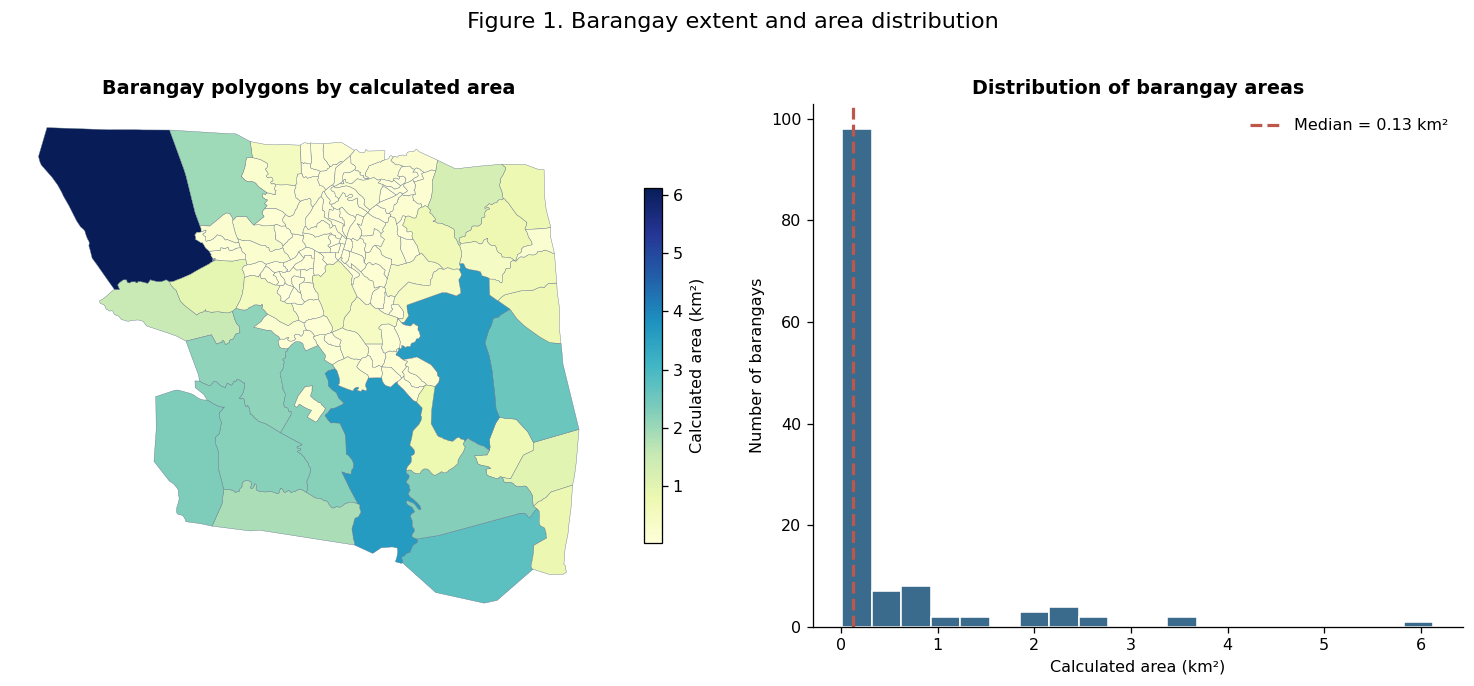

In [5]:
fig, (ax_map, ax_dist) = plt.subplots(1, 2, figsize=(13, 5.8),
                                     gridspec_kw={'width_ratios': [1.16, 1]})
bar_proj.plot(ax=ax_map, column='area_calculated_km2', cmap='YlGnBu',
              legend=True, edgecolor='#64748b', linewidth=0.25,
              legend_kwds={'label': 'Calculated area (km²)', 'shrink': 0.68})
ax_map.set_title('Barangay polygons by calculated area')
ax_map.set_axis_off()
area_values = bar_proj['area_calculated_km2'].dropna()
ax_dist.hist(area_values, bins=20, color='#3a6b8d', edgecolor='white')
ax_dist.axvline(area_values.median(), color='#be574b', linestyle='--',
                linewidth=2, label=f'Median = {area_values.median():.2f} km²')
ax_dist.set(title='Distribution of barangay areas', xlabel='Calculated area (km²)',
            ylabel='Number of barangays')
ax_dist.legend(frameon=False)
fig.suptitle('Figure 1. Barangay extent and area distribution', y=1.02, fontsize=14)
fig.tight_layout()
save_figure(fig, '01_barangay_areas.png')
plt.show()

## 4. Road network: attributes, geometry, and connectivity

The GraphML dataset is evaluated as a **directed multigraph**. Weakly connected components indicate disconnected road clusters if edge direction is ignored. Strong connectivity is reported separately and is not sufficient to establish hospital routability, access permissions, or travel time.

When road-edge geometry is absent, a straight segment between graph nodes is used only in the diagnostic figures and nearest-edge screening. It is **not** a replacement for actual road geometry in routing analysis.

In [6]:
node_rows, invalid_node_ids = [], []
for node_id, attrs in G.nodes(data=True):
    x, y = pd.to_numeric(attrs.get('x'), errors='coerce'), pd.to_numeric(attrs.get('y'), errors='coerce')
    if pd.isna(x) or pd.isna(y) or not (np.isfinite(x) and np.isfinite(y)):
        invalid_node_ids.append(node_id)
    else:
        node_rows.append({'node_id': str(node_id), 'x': float(x), 'y': float(y)})
add_check('roads', 'node_coordinates', 'PASS' if not invalid_node_ids else 'FAIL',
          f'{len(invalid_node_ids)} nodes with invalid x/y')
if invalid_node_ids:
    raise ValueError(f'Invalid node coordinates: {invalid_node_ids[:5]}')

nodes_frame = pd.DataFrame(node_rows)
nodes_geo = gpd.GeoDataFrame(nodes_frame,
    geometry=gpd.points_from_xy(nodes_frame.x, nodes_frame.y), crs=graph_crs)
nodes_proj = nodes_geo.to_crs(PROJECTED_CRS)
nodes_wgs = nodes_geo.to_crs(GEOGRAPHIC_CRS)
graph_bbox = tuple(float(x) for x in nodes_wgs.total_bounds)

edge_rows = []
geometry_fallback_count = 0
geometry_parse_errors = 0
for u, v, k, attrs in G.edges(keys=True, data=True):
    length_m = pd.to_numeric(attrs.get('length'), errors='coerce')
    raw_geom = attrs.get('geometry')
    geom = None
    if raw_geom is not None and str(raw_geom).strip():
        try:
            geom = wkt.loads(raw_geom) if isinstance(raw_geom, str) else raw_geom
        except Exception:
            geometry_parse_errors += 1
    if geom is None or geom.is_empty or geom.geom_type not in ('LineString', 'MultiLineString'):
        geometry_fallback_count += 1
        geom = LineString([(float(G.nodes[u]['x']), float(G.nodes[u]['y'])),
                           (float(G.nodes[v]['x']), float(G.nodes[v]['y']))])
    edge_rows.append({'u': str(u), 'v': str(v), 'key': str(k),
                      'length_m': float(length_m) if pd.notna(length_m) else np.nan,
                      'highway': str(attrs.get('highway', 'unspecified')),
                      'geometry': geom})
roads_geo = gpd.GeoDataFrame(edge_rows, geometry='geometry', crs=graph_crs)
roads_proj = roads_geo.to_crs(PROJECTED_CRS)
roads_wgs = roads_geo.to_crs(GEOGRAPHIC_CRS)

bad_lengths = roads_geo.length_m.isna() | (roads_geo.length_m <= 0)
add_check('roads', 'positive_edge_lengths', 'PASS' if not bad_lengths.any() else 'FAIL',
          f'{bad_lengths.sum()} missing or nonpositive edge lengths')
add_check('roads', 'edge_geometry_parsing', 'PASS' if not geometry_parse_errors else 'WARN',
          f'{geometry_parse_errors} WKT parse errors; {geometry_fallback_count} straight-segment fallbacks')

weak_components = (sorted((len(c) for c in nx.weakly_connected_components(G)), reverse=True)
                   if G.is_directed() else sorted((len(c) for c in nx.connected_components(G)), reverse=True))
strong_count = (nx.number_strongly_connected_components(G) if G.is_directed() else None)
largest_weak_share = 100 * weak_components[0] / G.number_of_nodes()
add_check('roads', 'weak_component_count', 'PASS' if len(weak_components) == 1 else 'WARN',
          f'{len(weak_components)} weak components; largest contains {largest_weak_share:.1f}% of nodes')

graph_stats = pd.DataFrame([
    ['Nodes', G.number_of_nodes()], ['Directed edges', G.number_of_edges()],
    ['Weak components', len(weak_components)], ['Strong components', strong_count],
    ['Largest weak component (%)', round(largest_weak_share, 2)],
    ['Missing/nonpositive lengths', int(bad_lengths.sum())],
    ['Edges drawn using endpoint fallback', geometry_fallback_count],
], columns=['measure', 'value'])
display(graph_stats)

,measure,value
0,Nodes,3745.00
1,Directed edges,8077.00
2,Weak components,28.00
3,Strong components,42.00
4,Largest weak component (%),97.62
5,Missing/nonpositive lengths,0.00
6,Edges drawn using endpoint fallback,1437.00


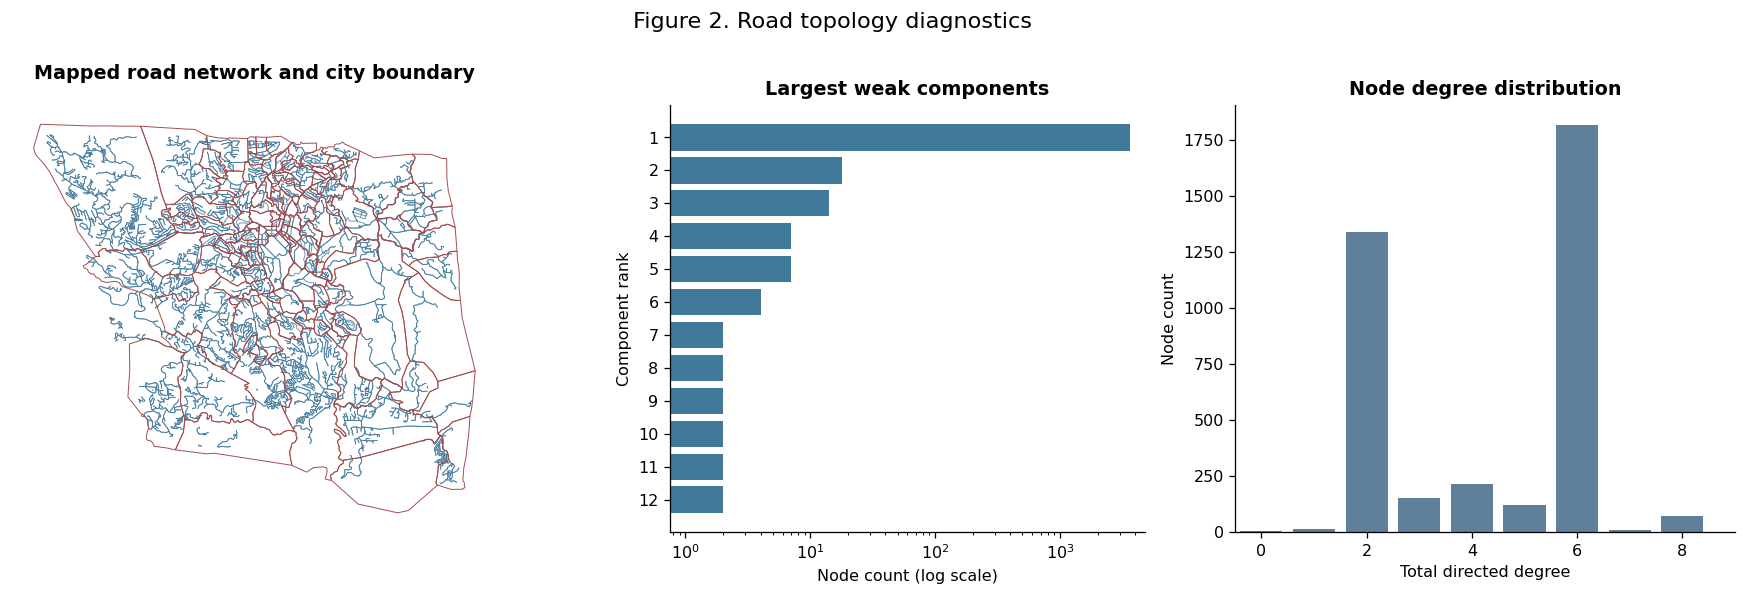

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5), gridspec_kw={'width_ratios': [1.3, 0.95, 1]})
roads_proj.plot(ax=axes[0], linewidth=0.55, color='#41799b', alpha=0.85)
bar_proj.boundary.plot(ax=axes[0], linewidth=0.6, color='#a14c4c')
axes[0].set(title='Mapped road network and city boundary')
axes[0].set_axis_off()

component_top = weak_components[:12]
axes[1].barh(range(len(component_top)), component_top, color='#41799b')
axes[1].invert_yaxis()
axes[1].set_yticks(range(len(component_top)), [f'{i+1}' for i in range(len(component_top))])
axes[1].set_xscale('log')
axes[1].set_xlim(0.75, max(component_top) * 1.3)
axes[1].set(title='Largest weak components', xlabel='Node count (log scale)', ylabel='Component rank')

node_degrees = np.array([degree for _, degree in G.degree()], dtype=int)
max_degree = int(node_degrees.max())
counts = np.bincount(node_degrees, minlength=max_degree + 1)
axes[2].bar(np.arange(len(counts)), counts, color='#607f9b', width=0.8)
axes[2].set(title='Node degree distribution', xlabel='Total directed degree',
            ylabel='Node count')
axes[2].set_xlim(-0.5, min(max_degree + 1, 15))
fig.suptitle('Figure 2. Road topology diagnostics', y=1.025, fontsize=14)
fig.tight_layout()
save_figure(fig, '02_road_topology.png')
plt.show()

## 5. Susceptibility polygons: geometry and mapped coverage

Invalid input geometries are identified and reported. In-memory geometry repair is applied **only** for diagnostic plotting and intersection calculations, leaving the original GeoJSON unchanged. A future preprocessing notebook must explicitly document any persisted geometry correction.

`LndslideSusc` is categorical: class meanings and source provenance require external confirmation. The calculated area by class represents intersected polygon area, not observed landslide incidence or road-closure frequency.

In [8]:
land_missing = landslides.geometry.isna() | landslides.geometry.is_empty
land_invalid = ~landslides.geometry.is_valid
invalid_details = pd.DataFrame([
    {'OBJECTID': r.OBJECTID, 'LndslideSusc': r.LndslideSusc,
     'issue': explain_validity(r.geometry)}
    for r in landslides.loc[land_invalid].itertuples()
])
add_check('landslides', 'nonempty_geometry', 'PASS' if not land_missing.any() else 'FAIL',
          f'{land_missing.sum()} missing/empty geometries')
add_check('landslides', 'valid_polygon_geometry', 'PASS' if not land_invalid.any() else 'WARN',
          f'{land_invalid.sum()} invalid source geometries')
add_check('landslides', 'nonmissing_susceptibility_code',
          'PASS' if landslides['LndslideSusc'].notna().all() else 'WARN',
          f'{landslides.LndslideSusc.isna().sum()} missing classes')
if not invalid_details.empty:
    display(invalid_details)

land_proj = landslides.to_crs(PROJECTED_CRS).copy()

def polygonal_part(geom):
    """Retain polygonal components from a diagnostic make_valid result."""
    if geom is None or geom.is_empty:
        return GeometryCollection()
    repaired = make_valid(geom)
    if repaired.geom_type in ('Polygon', 'MultiPolygon'):
        return repaired
    polygon_parts = []
    stack = [repaired]
    while stack:
        part = stack.pop()
        if part.geom_type in ('Polygon', 'MultiPolygon'):
            polygon_parts.append(part)
        elif hasattr(part, 'geoms'):
            stack.extend(part.geoms)
    return unary_union(polygon_parts) if polygon_parts else GeometryCollection()

land_proj['geometry'] = land_proj.geometry.apply(polygonal_part)
land_proj['within_city_geometry'] = land_proj.geometry.intersection(city_proj)
land_proj['area_within_city_km2'] = land_proj.within_city_geometry.area / 1e6
land_proj['intersects_city'] = land_proj.geometry.intersects(city_proj)

intersections = [geom for geom in land_proj.within_city_geometry if geom is not None and not geom.is_empty]
covered_shape = union_all(intersections) if intersections else GeometryCollection()
coverage_pct = 100 * covered_shape.area / city_proj.area
add_check('landslides', 'study_area_coverage', 'PASS' if coverage_pct >= 99.9 else 'WARN',
          f'{coverage_pct:.2f}% of city union covered by mapped susceptibility polygons')

class_counts = landslides['LndslideSusc'].value_counts(dropna=False).rename('features')
class_areas = land_proj.groupby('LndslideSusc', dropna=False)['area_within_city_km2'].sum()
class_summary = pd.concat([class_counts, class_areas], axis=1).fillna(0).reset_index()
class_summary.columns = ['class_code', 'polygon_features', 'mapped_area_km2']
class_summary['class_code'] = class_summary.class_code.astype(str)
class_summary['sort_key'] = class_summary.class_code.map({c:i for i,c in enumerate(CLASS_ORDER)}).fillna(99)
class_summary = class_summary.sort_values(['sort_key', 'class_code']).drop(columns='sort_key')
display(class_summary.round(3))
print(f'Study-area footprint covered by mapped polygons: {coverage_pct:.2f}%')
print(f'Source invalid features: {land_invalid.sum()} / {len(landslides)}')

,OBJECTID,LndslideSusc,issue
0,1712922,HL,Ring Self-intersection[120.490452436659 16.498...
1,1714750,LL,Ring Self-intersection[120.559539558287 16.397...


,class_code,polygon_features,mapped_area_km2
2,LL,9,0.411
1,ML,10,10.674
3,HL,7,36.395
0,VHL,20,8.017
4,DF,1,0.068


Study-area footprint covered by mapped polygons: 95.58%
Source invalid features: 2 / 47


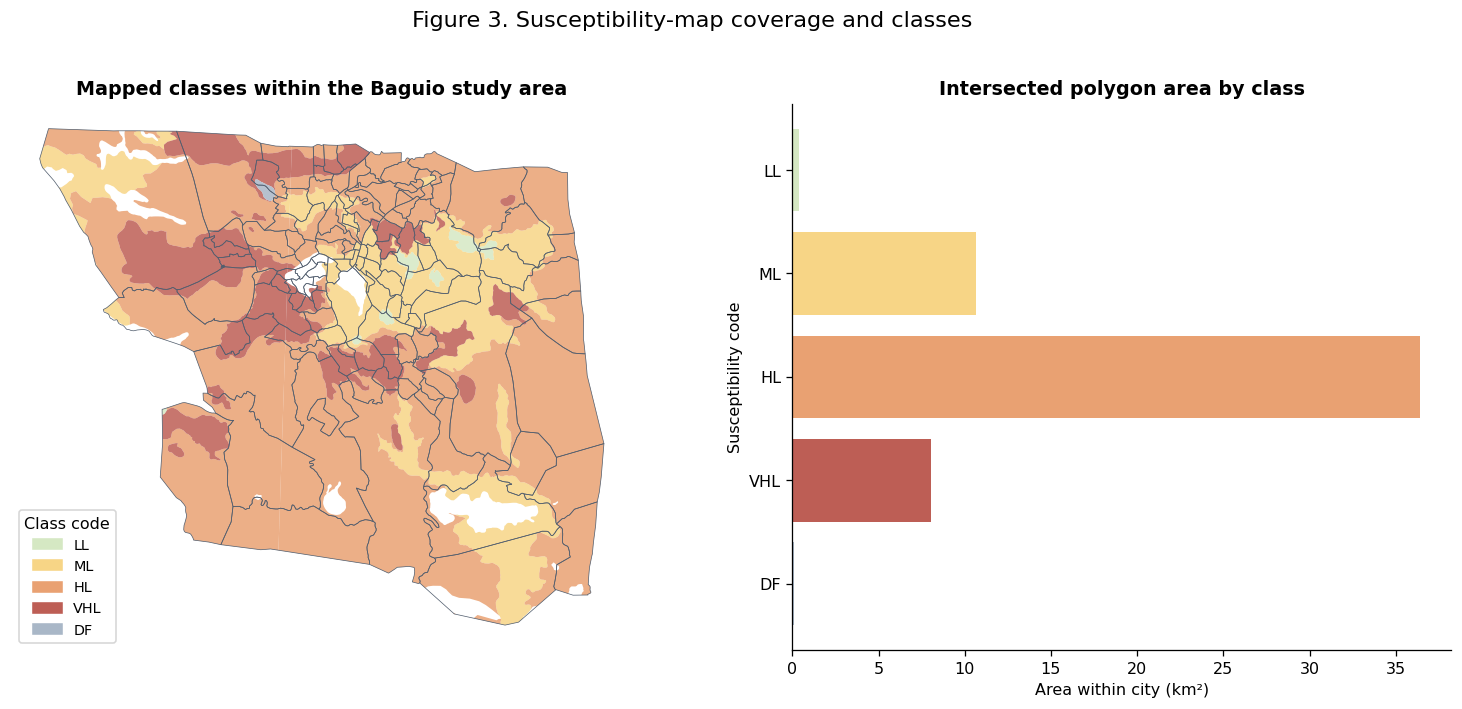

In [9]:
fig, (ax_map, ax_class) = plt.subplots(1, 2, figsize=(13.5, 6),
                                      gridspec_kw={'width_ratios': [1.18, 1]})
for category in CLASS_ORDER + sorted(set(class_summary.class_code) - set(CLASS_ORDER)):
    group = land_proj[(land_proj.LndslideSusc.astype(str) == category)
                      & (land_proj.area_within_city_km2 > 0)].copy()
    if len(group):
        gpd.GeoSeries(group.within_city_geometry, crs=PROJECTED_CRS).plot(
            ax=ax_map, color=CLASS_COLORS.get(category, '#b9bac0'),
            edgecolor='none', alpha=0.85)
bar_proj.boundary.plot(ax=ax_map, color='#525e6e', linewidth=0.45)
ax_map.set(title='Mapped classes within the Baguio study area')
ax_map.set_axis_off()
legend_categories = class_summary.class_code.tolist()
ax_map.legend(handles=[Patch(color=CLASS_COLORS.get(c, '#b9bac0'), label=c)
                       for c in legend_categories],
              title='Class code', loc='lower left', frameon=True, fontsize=9)

ax_class.barh(class_summary.class_code, class_summary.mapped_area_km2,
              color=[CLASS_COLORS.get(c, '#b9bac0') for c in class_summary.class_code])
ax_class.invert_yaxis()
ax_class.set(title='Intersected polygon area by class', xlabel='Area within city (km²)',
             ylabel='Susceptibility code')
fig.suptitle('Figure 3. Susceptibility-map coverage and classes', y=1.02, fontsize=14)
fig.tight_layout()
save_figure(fig, '03_susceptibility_classes.png')
plt.show()

## 6. Hospital entrance and network-coverage audit

Hospital coordinates are interpreted as longitude/latitude WGS 84. Audit flags are recalculated from the spatial layers rather than relying on pre-existing spreadsheet labels. Nearest-edge distances are measured to the current mapped road geometries using projected coordinates; they provide **screening information only**, not confirmed connections or travel routes.

Entrances beyond the city boundary may still be relevant to actual hospital access. Excluding them without a documented study-area decision would bias later accessibility analyses.

In [10]:
entrance_ids = hospitals['entrance_id'].astype('string')
missing_entrance_ids = int(entrance_ids.isna().sum())
duplicate_entrance_ids = int(entrance_ids.dropna().duplicated().sum())
add_check('hospitals', 'unique_entrance_ids',
          'PASS' if missing_entrance_ids + duplicate_entrance_ids == 0 else 'WARN',
          f'{missing_entrance_ids} missing; {duplicate_entrance_ids} duplicate')

lat = pd.to_numeric(hospitals['entrance_latitude'], errors='coerce')
lon = pd.to_numeric(hospitals['entrance_longitude'], errors='coerce')
coords_ok = lat.between(-90, 90) & lon.between(-180, 180)
add_check('hospitals', 'valid_coordinates', 'PASS' if coords_ok.all() else 'FAIL',
          f'{(~coords_ok).sum()} invalid/missing latitude-longitude pairs')
if not coords_ok.all():
    raise ValueError('Hospital coordinates missing or outside valid latitude/longitude ranges.')

hosp_geo = gpd.GeoDataFrame(hospitals.copy(),
    geometry=gpd.points_from_xy(lon, lat), crs=GEOGRAPHIC_CRS)
hosp_geo['source_row_id'] = np.arange(len(hosp_geo))
hosp_proj = hosp_geo.to_crs(PROJECTED_CRS)
hosp_geo['inside_city_polygon'] = hosp_proj.geometry.apply(city_proj.covers).to_numpy()
hosp_geo['inside_graph_bbox'] = (
    lon.between(graph_bbox[0], graph_bbox[2]) &
    lat.between(graph_bbox[1], graph_bbox[3])
).to_numpy()

# A spatial index accelerates nearest-edge screening. Multiple equidistant directed
# edges are reduced to one result per entrance.
nearest = gpd.sjoin_nearest(
    hosp_proj[['source_row_id', 'geometry']],
    roads_proj[['geometry']], how='left', distance_col='distance_to_road_m'
)
nearest_distance = nearest.groupby('source_row_id')['distance_to_road_m'].min()
hosp_geo['computed_nearest_road_m'] = hosp_geo.source_row_id.map(nearest_distance)

reported_distance = pd.to_numeric(hosp_geo.get('nearest_edge_distance_m',
    pd.Series(index=hosp_geo.index, dtype=float)), errors='coerce')
hosp_geo['reported_nearest_road_m'] = reported_distance
hosp_geo['reported_vs_computed_delta_m'] = (
    hosp_geo['reported_nearest_road_m'] - hosp_geo['computed_nearest_road_m']
)

def normalized_id(value):
    if pd.isna(value):
        return None
    string = str(value).strip()
    if string.endswith('.0') and string[:-2].isdigit():
        return string[:-2]
    return string

def referenced_edge_exists(r):
    fields = ('nearest_edge_u', 'nearest_edge_v', 'nearest_edge_key')
    if not all(f in r.index for f in fields):
        return False
    u, v, key = [normalized_id(r[f]) for f in fields]
    if u is None or v is None or key is None or not G.has_edge(u, v):
        return False
    return any(str(k) == key for k in G[u][v].keys())

hosp_geo['referenced_edge_exists'] = hospitals.apply(referenced_edge_exists, axis=1)
if 'nearest_graph_node_id' in hospitals.columns:
    hosp_geo['referenced_node_exists'] = hospitals['nearest_graph_node_id'].apply(
        lambda x: normalized_id(x) in G)
else:
    hosp_geo['referenced_node_exists'] = False

verified = (hosp_geo.get('gate_verified', pd.Series(index=hosp_geo.index, dtype=str))
            .astype('string').str.strip().str.upper().eq('YES').fillna(False))
hosp_geo['gate_verified_flag'] = verified.astype(bool)
hosp_geo['distance_review_flag'] = hosp_geo.computed_nearest_road_m > SNAP_REVIEW_THRESHOLD_M

add_check('hospitals', 'inside_graph_bbox',
          'PASS' if hosp_geo.inside_graph_bbox.all() else 'WARN',
          f'{(~hosp_geo.inside_graph_bbox).sum()} entrances outside network node bounding box')
add_check('hospitals', 'inside_city_polygon',
          'PASS' if hosp_geo.inside_city_polygon.all() else 'WARN',
          f'{(~hosp_geo.inside_city_polygon).sum()} entrances outside city study polygon')
add_check('hospitals', 'verified_entrances',
          'PASS' if hosp_geo.gate_verified_flag.all() else 'WARN',
          f'{(~hosp_geo.gate_verified_flag).sum()} not marked as verified')
add_check('hospitals', 'referenced_graph_edges',
          'PASS' if hosp_geo.referenced_edge_exists.all() else 'WARN',
          f'{(~hosp_geo.referenced_edge_exists).sum()} references absent from graph')
add_check('hospitals', 'nearest_road_screening',
          'PASS' if not hosp_geo.distance_review_flag.any() else 'WARN',
          f'{hosp_geo.distance_review_flag.sum()} beyond {SNAP_REVIEW_THRESHOLD_M:.0f} m diagnostic threshold')

hospital_audit = pd.DataFrame(hosp_geo.drop(columns='geometry'))[[
    'entrance_id', 'hospital_name', 'entrance_latitude', 'entrance_longitude',
    'inside_city_polygon', 'inside_graph_bbox', 'computed_nearest_road_m',
    'reported_nearest_road_m', 'reported_vs_computed_delta_m',
    'referenced_node_exists', 'referenced_edge_exists',
    'gate_verified_flag', 'distance_review_flag',
]].copy()
display(hospital_audit.round(2))

,entrance_id,hospital_name,entrance_latitude,entrance_longitude,inside_city_polygon,inside_graph_bbox,computed_nearest_road_m,reported_nearest_road_m,reported_vs_computed_delta_m,referenced_node_exists,referenced_edge_exists,gate_verified_flag,distance_review_flag
0,NDCH-P01,Notre Dame de Chartres Hospital,16.41,120.60,True,True,2.40,2.4,0.00,True,True,False,False
1,SHMC-P01,SLU Hospital of the Sacred Heart Medical Center,16.42,120.60,True,True,1.10,1.1,0.00,True,True,False,False
2,CHDG-P01,Cordillera Hospital of the Divine Grace,16.45,120.57,False,False,2253.42,2253.4,-0.02,True,True,False,True
3,CHDG-P02,Cordillera Hospital of the Divine Grace,16.45,120.57,False,False,2266.09,2266.1,0.01,True,True,False,True


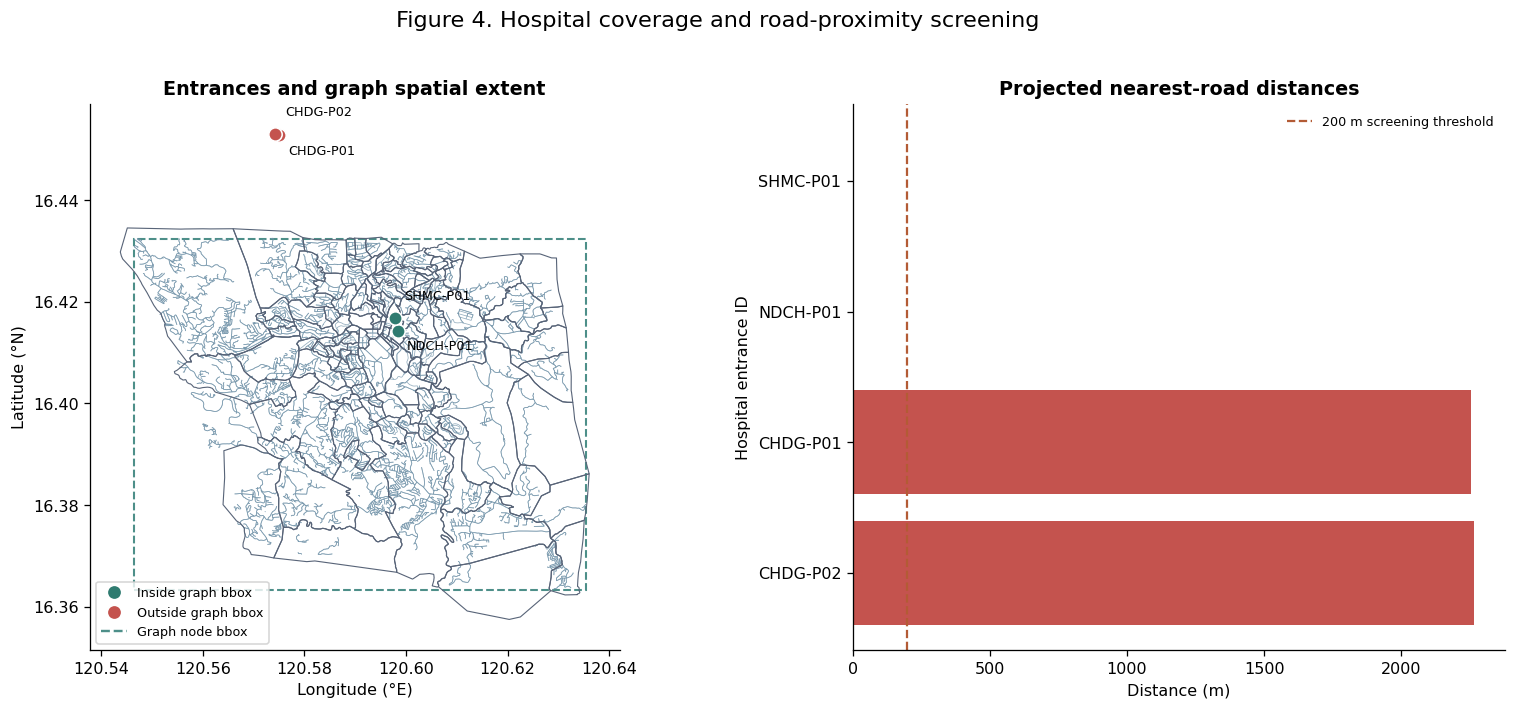

In [11]:
fig, (ax_map, ax_dist) = plt.subplots(1, 2, figsize=(14, 6),
                                      gridspec_kw={'width_ratios': [1.23, 1]})
roads_wgs.plot(ax=ax_map, linewidth=0.48, color='#7193a9', alpha=0.75)
barangays.boundary.plot(ax=ax_map, linewidth=0.7, color='#586478')
ax_map.add_patch(Rectangle((graph_bbox[0], graph_bbox[1]),
                           graph_bbox[2] - graph_bbox[0], graph_bbox[3] - graph_bbox[1],
                           linewidth=1.3, edgecolor='#4d8f89', facecolor='none', linestyle='--'))
for i, (_, r) in enumerate(hosp_geo.iterrows()):
    color = '#2f7b70' if r.inside_graph_bbox else '#c4534e'
    ax_map.scatter(r.geometry.x, r.geometry.y, s=70, marker='o',
                   facecolor=color, edgecolor='white', linewidth=1, zorder=5)
    ax_map.annotate(str(r.entrance_id), (r.geometry.x, r.geometry.y),
                    xytext=(6, -12 if i % 2 == 0 else 12),
                    textcoords='offset points', fontsize=8)
ax_map.legend(handles=[
    Line2D([0], [0], marker='o', color='none', markerfacecolor='#2f7b70',
           markeredgecolor='white', markersize=9, label='Inside graph bbox'),
    Line2D([0], [0], marker='o', color='none', markerfacecolor='#c4534e',
           markeredgecolor='white', markersize=9, label='Outside graph bbox'),
    Line2D([0], [0], color='#4d8f89', linestyle='--', label='Graph node bbox'),
], loc='lower left', fontsize=8, frameon=True)
minx = min(barangays.total_bounds[0], hosp_geo.total_bounds[0]) - 0.006
maxx = max(barangays.total_bounds[2], hosp_geo.total_bounds[2]) + 0.006
miny = min(barangays.total_bounds[1], hosp_geo.total_bounds[1]) - 0.006
maxy = max(barangays.total_bounds[3], hosp_geo.total_bounds[3]) + 0.006
ax_map.set(xlim=(minx,maxx), ylim=(miny,maxy), title='Entrances and graph spatial extent',
           xlabel='Longitude (°E)', ylabel='Latitude (°N)')
ax_map.set_aspect('equal', adjustable='box')

hosp_sorted = hosp_geo.sort_values('computed_nearest_road_m')
colors = ['#c4534e' if x else '#2f7b70' for x in hosp_sorted.distance_review_flag]
ax_dist.barh(hosp_sorted.entrance_id.astype(str),
             hosp_sorted.computed_nearest_road_m, color=colors)
ax_dist.axvline(SNAP_REVIEW_THRESHOLD_M, linestyle='--', color='#b35b35',
                linewidth=1.4, label=f'{SNAP_REVIEW_THRESHOLD_M:.0f} m screening threshold')
ax_dist.invert_yaxis()
ax_dist.set(title='Projected nearest-road distances', xlabel='Distance (m)',
            ylabel='Hospital entrance ID')
ax_dist.legend(frameon=False, fontsize=8)
fig.suptitle('Figure 4. Hospital coverage and road-proximity screening', y=1.02, fontsize=14)
fig.tight_layout()
save_figure(fig, '04_hospital_coverage.png')
plt.show()

## 7. Integrated spatial overview

This map displays the relative extents of all four inputs for visual review. The susceptibility layer is rendered from a temporary in-memory validity repair and clipped to the city study polygon for readability. Hospital entrance coordinates are preliminary.

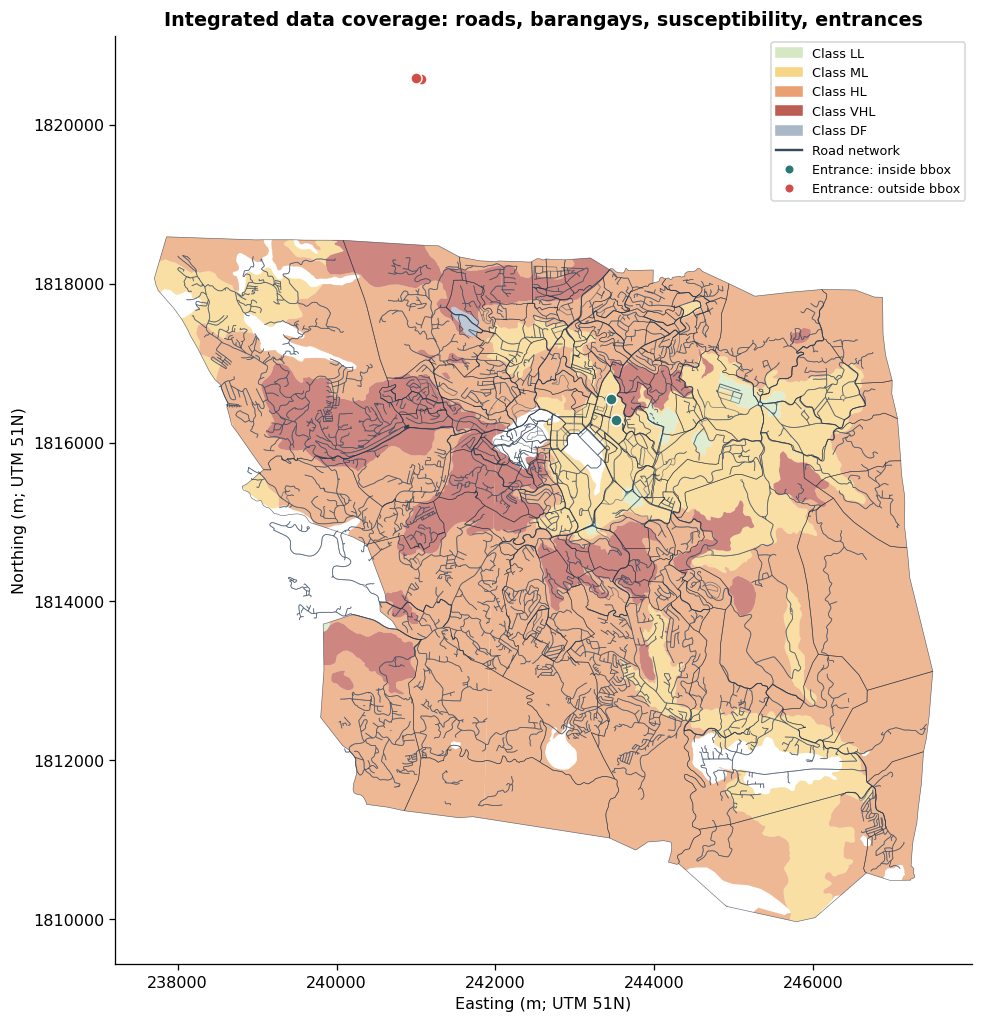

In [12]:
fig, ax = plt.subplots(figsize=(9, 9))
for category in CLASS_ORDER + sorted(set(class_summary.class_code) - set(CLASS_ORDER)):
    group = land_proj[(land_proj.LndslideSusc.astype(str) == category)
                      & (land_proj.area_within_city_km2 > 0)]
    if len(group):
        gpd.GeoSeries(group.within_city_geometry, crs=PROJECTED_CRS).plot(
            ax=ax, color=CLASS_COLORS.get(category, '#b9bac0'), linewidth=0, alpha=0.75)
roads_proj.plot(ax=ax, color='#354a62', linewidth=0.5, alpha=0.60)
bar_proj.boundary.plot(ax=ax, color='#202f42', linewidth=0.38, alpha=0.7)
for _, r in hosp_proj.iterrows():
    outside = not hosp_geo.loc[hosp_geo.source_row_id == r.source_row_id, 'inside_graph_bbox'].iloc[0]
    ax.scatter(r.geometry.x, r.geometry.y, s=48,
               c='#d14d45' if outside else '#2d7772',
               edgecolors='white', linewidths=0.9, zorder=7)
ax.set_title('Integrated data coverage: roads, barangays, susceptibility, entrances')
ax.set_xlabel('Easting (m; UTM 51N)')
ax.set_ylabel('Northing (m; UTM 51N)')
ax.set_aspect('equal', adjustable='box')
ax.ticklabel_format(style='plain', useOffset=False)
handles = [Patch(color=CLASS_COLORS.get(c, '#b9bac0'), label=f'Class {c}')
           for c in class_summary.class_code] + [
           Line2D([0], [0], color='#354a62', label='Road network'),
           Line2D([0], [0], marker='o', color='none', markerfacecolor='#2d7772',
                  markeredgecolor='white', label='Entrance: inside bbox'),
           Line2D([0], [0], marker='o', color='none', markerfacecolor='#d14d45',
                  markeredgecolor='white', label='Entrance: outside bbox')]
ax.legend(handles=handles, loc='upper right', fontsize=8, frameon=True)
fig.tight_layout()
save_figure(fig, '05_integrated_coverage.png')
plt.show()

## 8. Validation results and export

Check statuses distinguish definite structural failures (`FAIL`) from conditions requiring verification or methodological decisions (`WARN`). They are not a substitute for authoritative spatial data provenance or field validation.

,dataset,check,status,evidence
0,barangays,input_file_present,PASS,/Users/francie/Downloads/baguio-road-accessibi...
1,roads,input_file_present,PASS,/Users/francie/Downloads/baguio-road-accessibi...
2,landslides,input_file_present,PASS,/Users/francie/Downloads/baguio-road-accessibi...
3,hospitals,input_file_present,PASS,/Users/francie/Downloads/baguio-road-accessibi...
4,barangays,required_columns,PASS,All required columns present
5,landslides,required_columns,PASS,All required columns present
6,hospitals,required_columns,PASS,All required columns present
7,barangays,declared_crs,PASS,EPSG:4326
8,landslides,declared_crs,PASS,EPSG:4326
9,roads,declared_crs,PASS,epsg:4326


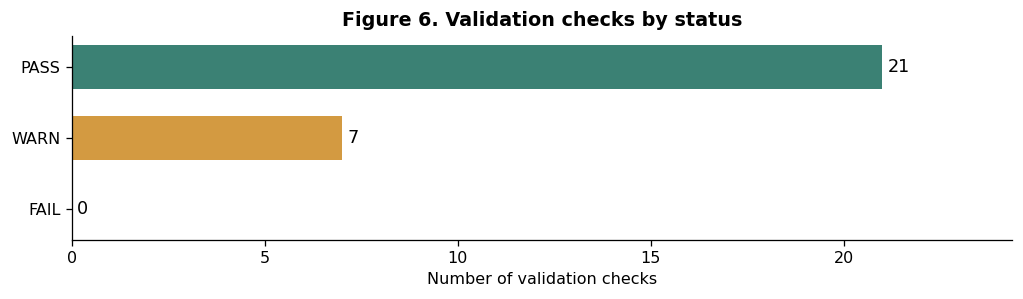

In [13]:
check_table = pd.DataFrame(checks)
status_counts = check_table.status.value_counts().reindex(['PASS', 'WARN', 'FAIL'], fill_value=0)
display(check_table)

fig, ax = plt.subplots(figsize=(9, 2.7))
colors = {'PASS':'#3b8174', 'WARN':'#d39a41', 'FAIL':'#b34e4e'}
ax.barh(status_counts.index, status_counts.values,
        color=[colors[s] for s in status_counts.index], height=0.62)
for i, number in enumerate(status_counts.values):
    ax.text(number + 0.14, i, str(int(number)), va='center', fontsize=11)
ax.invert_yaxis()
ax.set_xlim(0, max(status_counts.values.max() * 1.16, 2))
ax.set_xlabel('Number of validation checks')
ax.set_title('Figure 6. Validation checks by status')
fig.tight_layout()
save_figure(fig, '06_validation_check_summary.png')
plt.show()

In [14]:
def native_value(value):
    """Convert NumPy and pandas scalars to JSON-compatible Python values."""
    if isinstance(value, (np.integer,)):
        return int(value)
    if isinstance(value, (np.floating,)):
        return float(value)
    if isinstance(value, (np.bool_,)):
        return bool(value)
    return value

summary = {
    'report_name': 'Initial dataset validation and spatial QA',
    'generated_at_utc': datetime.now(timezone.utc).isoformat(timespec='seconds'),
    'projected_crs': PROJECTED_CRS,
    'raw_input_files': inventory.to_dict(orient='records'),
    'barangays': {
        'features': len(barangays), 'invalid_geometries': int(bar_invalid.sum()),
        'missing_psgc': int(bar_missing_ids), 'duplicate_psgc': int(bar_duplicate_ids),
        'area_sum_km2': round(float(bar_proj.area_calculated_km2.sum()), 4),
        'city_union_area_km2': round(float(city_proj.area / 1e6), 4),
        'zero_values_in_source_area_km2': int((bar_proj.area_source_km2 == 0).sum()),
    },
    'roads': {
        'directed': bool(G.is_directed()), 'nodes': G.number_of_nodes(),
        'directed_edges': G.number_of_edges(), 'weak_components': len(weak_components),
        'strong_components': strong_count, 'largest_weak_component_nodes': weak_components[0],
        'nonpositive_or_missing_edge_lengths': int(bad_lengths.sum()),
        'road_geometry_fallback_edges': int(geometry_fallback_count),
        'graph_node_bbox_wgs84': list(graph_bbox),
    },
    'landslides': {
        'features': len(landslides), 'invalid_geometries': int(land_invalid.sum()),
        'classes': {str(k): int(v) for k,v in landslides.LndslideSusc.value_counts(dropna=False).items()},
        'study_area_covered_percent': round(float(coverage_pct), 3),
    },
    'hospitals': {
        'entrances': len(hosp_geo),
        'unique_hospital_names': int(hosp_geo.hospital_name.nunique()),
        'outside_city_polygon': int((~hosp_geo.inside_city_polygon).sum()),
        'outside_graph_bbox': int((~hosp_geo.inside_graph_bbox).sum()),
        'unverified_entrances': int((~hosp_geo.gate_verified_flag).sum()),
        'missing_edge_references': int((~hosp_geo.referenced_edge_exists).sum()),
        'beyond_nearest_road_threshold': int(hosp_geo.distance_review_flag.sum()),
        'road_screening_threshold_m': SNAP_REVIEW_THRESHOLD_M,
    },
    'qa_checks': checks,
    'status_counts': {k: int(v) for k, v in status_counts.items()},
}
summary = json.loads(json.dumps(summary, default=native_value))
report_json = REPORT / 'validation_summary.json'
report_json.write_text(json.dumps(summary, indent=2, ensure_ascii=False), encoding='utf-8')
hospital_audit.to_csv(REPORT / 'hospital_access_audit.csv', index=False)
class_summary.to_csv(REPORT / 'susceptibility_class_summary.csv', index=False)

print('QA counts:', summary['status_counts'])
print('Report:', report_json.relative_to(ROOT))
print('Entrance audit:', (REPORT/'hospital_access_audit.csv').relative_to(ROOT))
print('Class summary:', (REPORT/'susceptibility_class_summary.csv').relative_to(ROOT))
print('Figures:', *[p.name for p in sorted(FIGURES.glob('*.png'))], sep='\n  ')

QA counts: {'PASS': 21, 'WARN': 7, 'FAIL': 0}
Report: reports/validation/validation_summary.json
Entrance audit: reports/validation/hospital_access_audit.csv
Class summary: reports/validation/susceptibility_class_summary.csv
Figures:
  01_barangay_areas.png
  02_road_topology.png
  03_susceptibility_classes.png
  04_hospital_coverage.png
  05_integrated_coverage.png
  06_validation_check_summary.png
